In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [2]:
df = pd.read_csv("train.csv")

print(df.head())

   ID Company Quarter  QuickRatio  InventoryRatio  RevenueGrowth  \
0   0   CMP01      Q1        2.02            7.71           0.05   
1   1   CMP01      Q2        2.01            4.10           0.03   
2   2   CMP01      Q3        2.02            6.79           0.06   
3   3   CMP01      Q4        1.98            3.97           0.01   
4   4   CMP01      Q5        1.96            7.41          -0.07   

   MarketshareChange Bond rating Stock rating Region           Industry  \
0              -0.04         CCC          Buy  South  Metal Fabrication   
1               0.00         CCC         Hold  South  Metal Fabrication   
2              -0.02         CCC          Buy  South  Metal Fabrication   
3               0.02         CCC          Buy  South  Metal Fabrication   
4               0.02         CCC          Buy  South  Metal Fabrication   

    Sales  
0  1517.0  
1  2968.0  
2  1497.0  
3  2929.0  
4  1452.0  


In [3]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 675 entries, 0 to 674
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 675 non-null    int64  
 1   Company            675 non-null    str    
 2   Quarter            675 non-null    str    
 3   QuickRatio         675 non-null    float64
 4   InventoryRatio     523 non-null    float64
 5   RevenueGrowth      675 non-null    float64
 6   MarketshareChange  675 non-null    float64
 7   Bond rating        675 non-null    str    
 8   Stock rating       675 non-null    str    
 9   Region             675 non-null    str    
 10  Industry           675 non-null    str    
 11  Sales              525 non-null    float64
dtypes: float64(5), int64(1), str(6)
memory usage: 63.4 KB
None


In [4]:
print(df.isnull().sum())

ID                     0
Company                0
Quarter                0
QuickRatio             0
InventoryRatio       152
RevenueGrowth          0
MarketshareChange      0
Bond rating            0
Stock rating           0
Region                 0
Industry               0
Sales                150
dtype: int64


In [5]:
df = df.dropna()

In [6]:
X = df[['QuickRatio', 'InventoryRatio', 'MarketshareChange']]

y = df['RevenueGrowth']

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [8]:
model = LinearRegression()

In [9]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [10]:
y_pred = model.predict(X_test)

In [11]:
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("R2 Score:", r2)

Mean Absolute Error: 0.054315506367623466
R2 Score: -0.06470205552196173


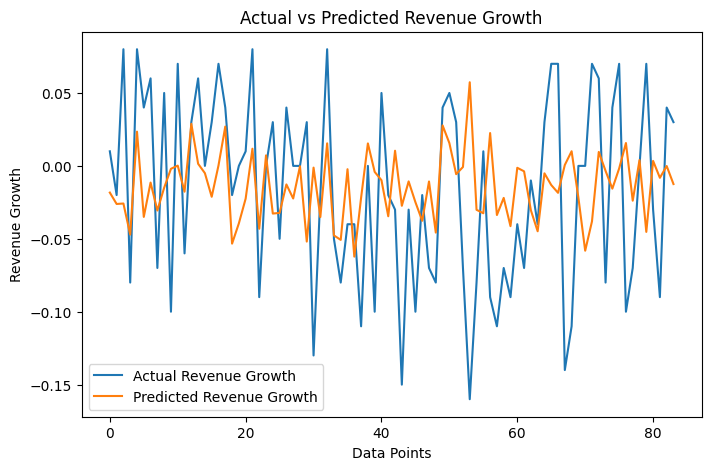

In [12]:
plt.figure(figsize=(8,5))

plt.plot(y_test.values, label='Actual Revenue Growth')
plt.plot(y_pred, label='Predicted Revenue Growth')

plt.title("Actual vs Predicted Revenue Growth")
plt.xlabel("Data Points")
plt.ylabel("Revenue Growth")

plt.legend()

plt.show()

In [13]:
results = pd.DataFrame({
    'Actual RevenueGrowth': y_test,
    'Predicted RevenueGrowth': y_pred
})

results.to_csv("predicted_results.csv", index=False)